# W09B · FM 이론과 개념 계산

**딥러닝응용I(추천시스템) · 동덕여자대학교 · 유원상 교수 · 2026-2**

2026-10-29 · 주교재 5.1–5.4. 사용자·아이템 원핫과 추가 특성으로 예측을 분해하고, 효율식·한 관측 갱신·희소 표현을 확인합니다. 전체 학습기는 다음 W10A에서 만듭니다.

CPU 런타임에서 파일 → Drive에 사본 저장 후 첫 셀부터 실행하세요. 설치 후 재시작 안내가 나오면 재시작하고 첫 셀부터 실행합니다. 고정 합성 모수이며 실제 데이터 다운로드는 없습니다. 계산을 먼저 예상하고 실행하세요. None은 학생 연습 빈칸입니다. 기본 기능 검사의 통과는 빈칸 답의 채점이 아닙니다.


In [ ]:
import os, sys, subprocess
os.environ['GRADIO_ANALYTICS_ENABLED'] = 'False'
IN_COLAB = 'google.colab' in sys.modules
COURSE_VERSION = '2026-fall-w09b'
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
        f'luna-recommender-course[apps] @ git+https://github.com/lunalab-ai/recommender.git@{COURSE_VERSION}',
        'gradio==6.26.0'], check=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from luna_recsys.fm_core import (toy_parameters, encode_observation, fm_score,
    fm_score_naive, pair_contributions, to_sparse, from_sparse,
    fm_score_sparse, prediction_gradients, fm_sgd_step)
from luna_recsys.fm_explainer import concept_view, build_fm_explainer
from luna_recsys.model_comparison import definition_link
print('Python', sys.version.split()[0], 'NumPy', np.__version__, '수업 버전', COURSE_VERSION)


## 실제 API와 수식

`toy_parameters()`는 매번 새 합성 배열을, `encode_observation(user,item,context)`는 길이5의 x를 반환합니다. y는 별도입니다. `fm_score(x,w,V,bias)`는 예측·선형항·상호작용·차원별 합과 자기항의 사전입니다. `fm_score_naive`와 `fm_score_sparse`는 실수 예측을 반환합니다. `pair_contributions`는 활성 쌍 표의 원자료입니다.

`prediction_gradients(x,V)`는 손실이 아닌 예측의 미분 사전입니다. `fm_sgd_step(x,y,w,V,bias,learning_rate)`는 절편 고정·정규화0인 한 단계의 새 모수와 전후 결과를 반환하며 입력을 변경하지 않습니다. 각 함수의 실제 선언 줄을 고정 태그로 연결합니다.


In [ ]:
apis = [toy_parameters, encode_observation, fm_score, fm_score_naive,
        pair_contributions, to_sparse, from_sparse, fm_score_sparse,
        prediction_gradients, fm_sgd_step, concept_view, build_fm_explainer]
display(Markdown('\n'.join(f'- [{f.__name__}]({definition_link(f, COURSE_VERSION)})' for f in apis)))
p = toy_parameters()
x = encode_observation('A', 'P', 1)
y = 4.
display(pd.DataFrame({'feature': p['names'], 'x': x, 'w': p['w'],
                      'v_f1': p['V'][:,0], 'v_f2': p['V'][:,1]}))
print('정답 y는 별도:', y, 'V shape:', p['V'].shape)


## E03·E05 · 쌍별 합과 효율식

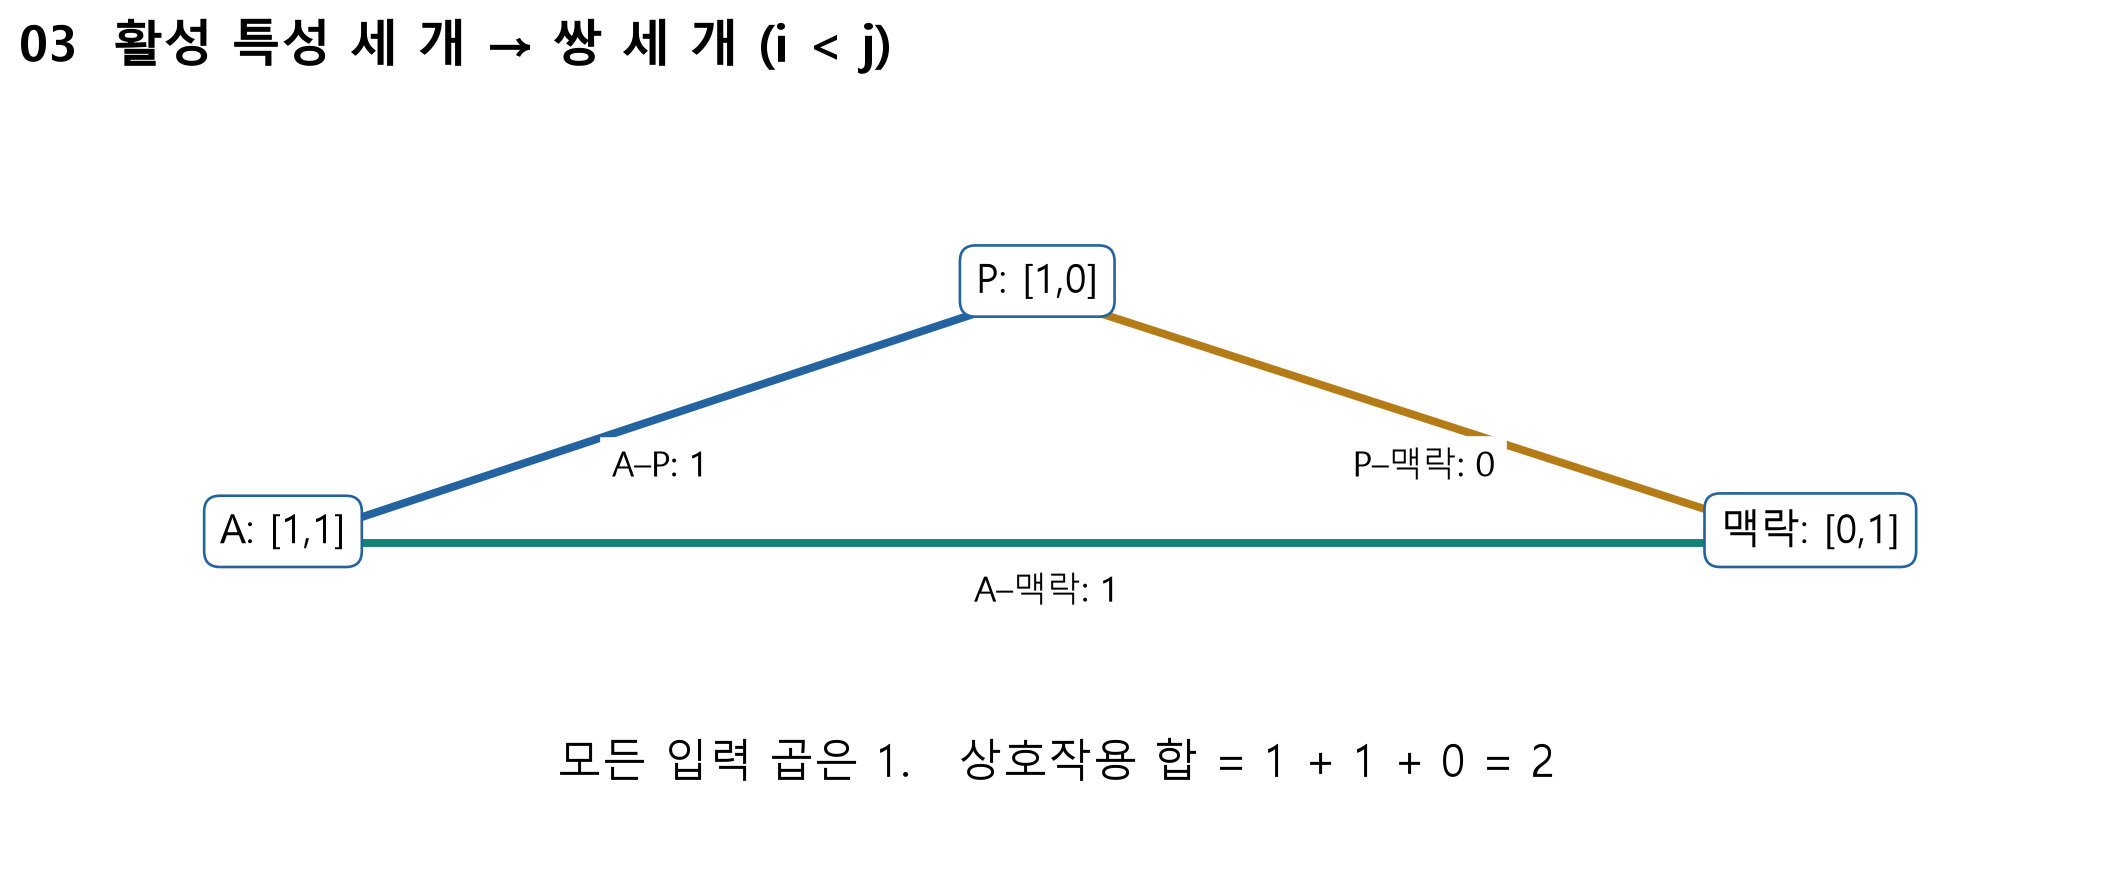

먼저 예측을 예상하세요. 절편·선형항·상호작용을 나누고 활성 쌍 세 개를 모두 적습니다. 내적이 0인 쌍도 표에 남깁니다. 효율식은 같은 값을 차원별로 계산합니다.


[Figure source](https://raw.githubusercontent.com/lunalab-ai/recommender/2026-fall-w09b/course/notion/assets/w09b/03-active-pairs.png)


In [ ]:
r = fm_score(x, p['w'], p['V'], p['bias'])
display(pd.DataFrame(pair_contributions(x,p['V'])))
display(pd.DataFrame({'S': r['factor_sums'], 'D': r['factor_self'],
                      '0.5*(S²-D)': r['factor_interactions']}))
print({key:r[key] for key in ['bias','linear','interaction','prediction']})
print('직접식:', fm_score_naive(x,p['w'],p['V'],p['bias']))


## L01–L04 · 독립 계산

워크북 L01의 B/Q/context0 입력과 y를 분리합니다. L02는 일반 수치 특성 네 개의 쌍 수입니다. L03은 x=[1,1,1], bias=.5,w=[.2,-.1,.4], V행=[1,0],[0,1],[1,-1]의 예측입니다. L04의 한 차원 가중 값은 [1,2,-1]입니다. 먼저 종이에서 풀고 자신의 값을 빈칸에 넣으세요.


In [ ]:
l01_x = None
l01_y = None
l02_pair_count = None
l03_prediction = None
l04_interaction = None
print('내 계산:', l01_x,l01_y,l02_pair_count,l03_prediction,l04_interaction)


## E06 · 미분과 같은 이전 상태의 갱신

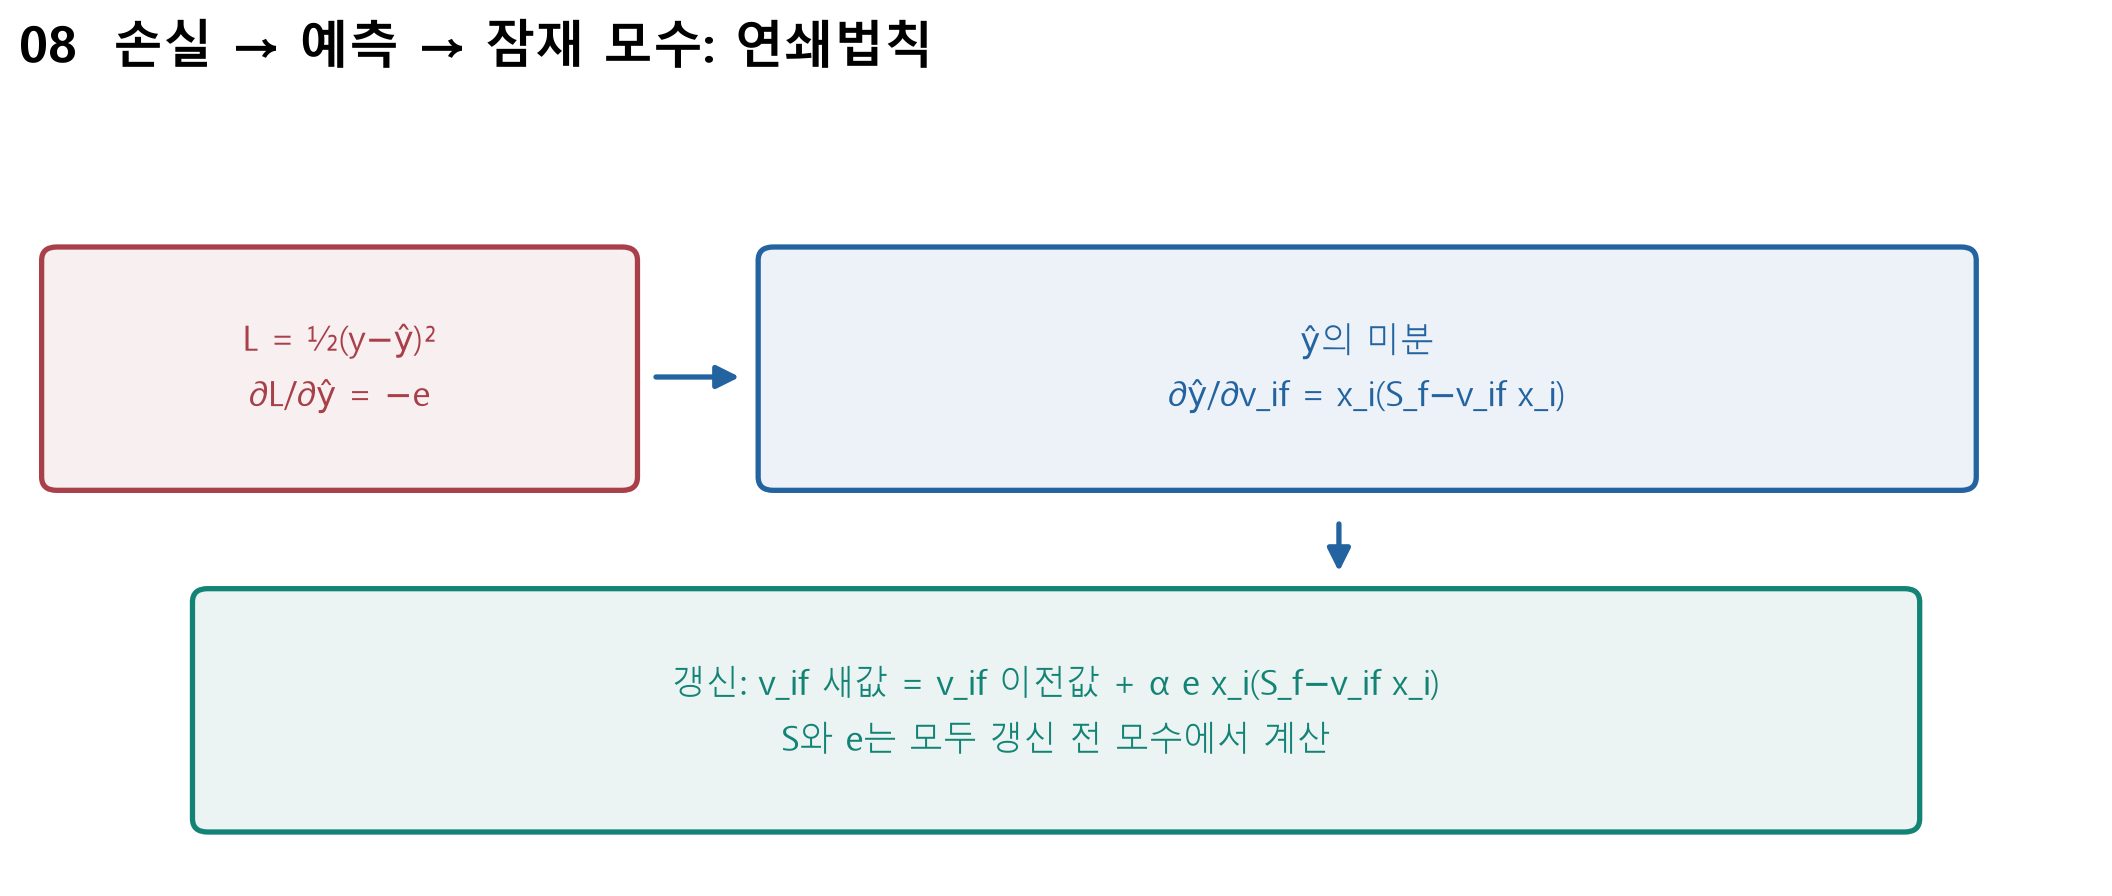

잔차는 e=y−예측, 손실은 0.5e²입니다. 예측 미분에 -e를 곱하면 손실 미분입니다. 모든 새 모수를 이전 상태에서 동시에 계산합니다. 원본 배열이 보존되는지도 확인합니다.


[Figure source](https://raw.githubusercontent.com/lunalab-ai/recommender/2026-fall-w09b/course/notion/assets/w09b/08-gradient-flow.png)


In [ ]:
g = prediction_gradients(x,p['V'])
display(pd.DataFrame(g['V'],index=p['names'],columns=['d_prediction/d_v1','d_prediction/d_v2']))
before_w,before_V=p['w'].copy(),p['V'].copy()
step=fm_sgd_step(x,y,p['w'],p['V'],p['bias'],.1)
display(pd.DataFrame({'feature':p['names'],'w_old':p['w'],'w_new':step['w'],
                      'v1_old':p['V'][:,0],'v1_new':step['V'][:,0],
                      'v2_old':p['V'][:,1],'v2_new':step['V'][:,1]}))
print('예측 전후:',step['prediction'],step['prediction_new'])
print('손실 전후:',step['loss'],step['loss_new'])
assert np.array_equal(before_w,p['w']) and np.array_equal(before_V,p['V'])
large=fm_sgd_step(x,y,p['w'],p['V'],p['bias'],1.)
print('학습률1의 손실 전후:',large['loss'],large['loss_new'])


## L05–L06 · 갱신과 희소 입력

L05: 이전 예측3,y4,α=.1,x_i=.5,w_i=.2,v_if=.4,S_f=2입니다. 예측 미분과 새 모수 두 개를 쓰세요. L06: x=[0,1,0,.5,0,-1]을 Python0기반 index/value로 바꾸세요. 값의 부호와 크기를 보존합니다.


In [ ]:
l05_grad_v = None
l05_w_new = None
l05_v_new = None
l06_indices = None
l06_values = None


## E07·E08 · 같은 입력의 희소 예측과 통제 비교

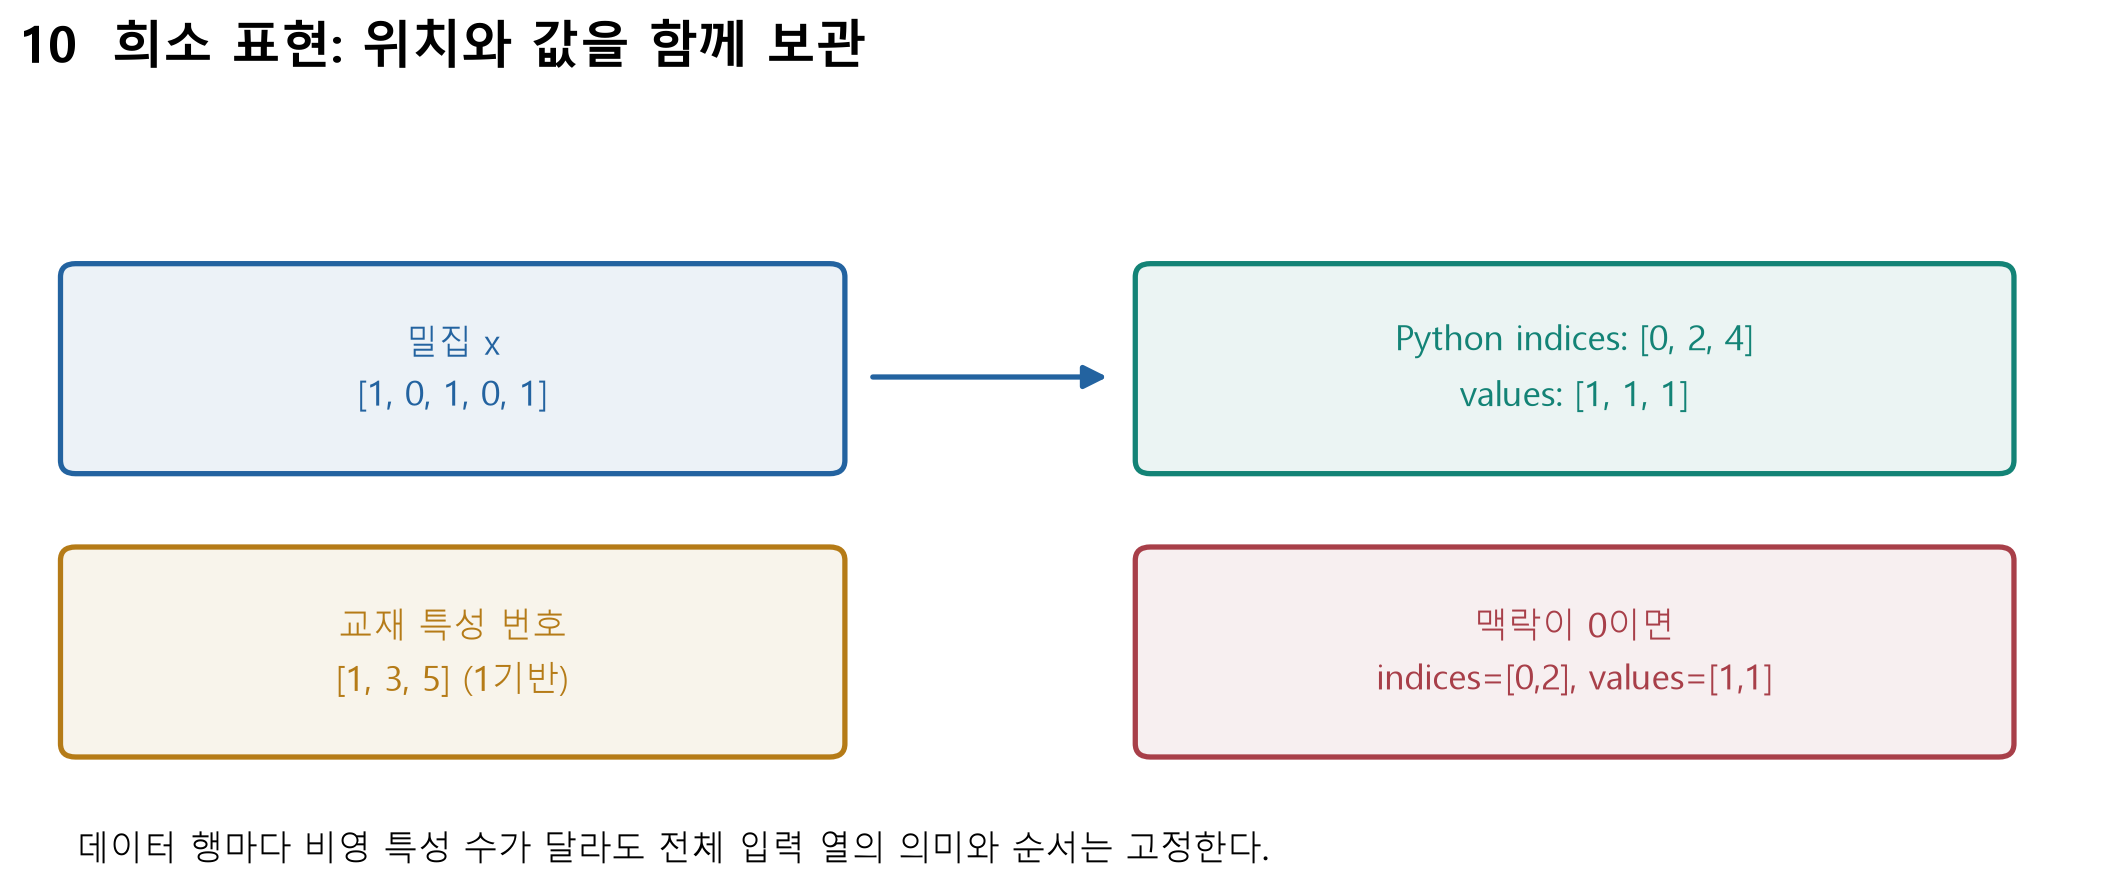

아래는 강의 공개 풀이 예제를 검산합니다. indices가 0기반인지 확인하세요. 맥락 하나만 바꾸고 어떤 기여가 달라지는지 적습니다. 이 값은 고정 모수의 계산이며 재학습된 성능 비교가 아닙니다.


[Figure source](https://raw.githubusercontent.com/lunalab-ai/recommender/2026-fall-w09b/course/notion/assets/w09b/10-dense-sparse.png)


In [ ]:
idx,values=to_sparse(x)
print('Python indices:',idx,'values:',values,'교재식 열 번호:',idx+1)
print('복원:',from_sparse(idx,values,len(x)))
print('희소 예측:',fm_score_sparse(idx,values,p['w'],p['V'],p['bias']))
rows=[]
for context in [0,1,2]:
    result=fm_score(encode_observation('A','P',context),p['w'],p['V'],p['bias'])
    rows.append({'context':context,**{key:result[key] for key in ['linear','interaction','prediction']}})
display(pd.DataFrame(rows))


## L07–L08 · 확장

L07: A와 Q의 각 벡터는 학습했지만 조합은 처음인 경우와, 열 사전에 없는 사용자 Z를 구별하세요. L08: x=[.5,2], V행=[2,0],[1,1]입니다. 자기항을 sum(V²*x)로 잘못 계산한 결과와 직접식의 결과를 비교하고 수정할 식을 쓰세요.


In [ ]:
l07_reason = ''
l08_correct_interaction = None
l08_wrong_interaction = None
l08_fix_reason = ''


## 개념 계산기 · 예상 후 버튼 누르기

`concept_view`는 실제 앱의 같은 callback입니다. 입력·쌍·희소·갱신 표와 그래프를 반환합니다. k=1은 첫 잠재 열만 쓰며 재학습이 아닙니다. 각 호출은 고정 합성 모수에서 다시 시작합니다. 전체 학습 앱 제작은 다음 차시입니다.


In [ ]:
summary,features,pairs,sparse,updates,figure=concept_view('A','P',1.,4.,.1,2)
print(summary)
display(features,pairs,sparse,updates,figure)
plt.close(figure)


### 선택 실행 · 앱 화면

Google Colab에서는 아래 셀이 Gradio 화면을 엽니다. 합성 입력만 쓰며 실제 개인정보나 정답 파일은 업로드하지 않습니다. 런타임 종료 시 링크도 종료됩니다. 로컬 일괄 검증은 서버를 띄우지 않고 같은 callback을 검사합니다.


In [ ]:
demo=build_fm_explainer()
if IN_COLAB:
    demo.launch(share=True,inline=True,debug=False)
else:
    print('로컬 검증: 앱 구성 및 실제 callback은 아래 runtime-check에서 확인합니다.')


## runtime-check · 기본 기능의 실제 검증

빈칸의 독립 정답을 공개하지 않는 기본 기능 검사입니다. 직접식·효율식·희소식, 공개 E예제, 한 모수의 수치 미분, 입력 변화와 callback 초기화를 검사합니다. 이 셀의 PASS는 Google Colab 화면·게시·모든 빈칸 채점을 대신하지 않습니다.


In [ ]:
assert np.isclose(r['prediction'],3.25)
assert np.isclose(r['prediction'],fm_score_naive(x,p['w'],p['V'],p['bias']))
assert np.isclose(r['prediction'],fm_score_sparse(idx,values,p['w'],p['V'],p['bias']))
assert np.isclose(step['prediction_new'],4.43125)
assert step['loss_new'] < step['loss'] and large['loss_new'] > large['loss']
h=1e-6
vp,vm=p['V'].copy(),p['V'].copy(); vp[0,0]+=h; vm[0,0]-=h
loss=lambda vv:.5*(y-fm_score(x,p['w'],vv,p['bias'])['prediction'])**2
numerical=(loss(vp)-loss(vm))/(2*h)
assert np.isclose(numerical,step['loss_gradient_V'][0,0],atol=1e-7)
v0=concept_view('A','P',0.,4.,.1,2)
v2=concept_view('A','P',2.,4.,.1,2)
v0_again=concept_view('A','P',0.,4.,.1,2)
assert v0[0] != v2[0] and v0[0] == v0_again[0]
assert len(v2[1])==5 and len(v2[2])==3
for view in [v0,v2,v0_again]: plt.close(view[-1])
assert len(demo.config['dependencies']) == 1
print('W09B_FM_RUNTIME_PASS: actual predictions, gradients, sparse input, callback, app configuration')


## 점검 퀴즈

1. FM에서 입력 차원 n과 잠재 차원 k는 각각 무엇을 세나요?
2. 2-way FM에서 i<j 조건은 어떤 두 종류의 중복을 막나요?
3. 선형항과 상호작용항은 각각 무엇을 나타내나요?
4. 사용자와 아이템 원핫만 활성인 FM을 편향이 있는 MF와 연결하려면 어떤 조건이 필요한가요?
5. 잠재벡터 공유는 관측되지 않은 조합의 예측에 어떻게 도움을 주며, 새 ID와는 어떻게 다른가요?
6. 효율식에서 자기항을 빼고 2로 나누는 이유는 무엇인가요?
7. 연속 입력을 허용할 때 자기항에서 입력값을 제곱해야 하는 이유는 무엇인가요?
8. e=y−예측일 때 제곱손실의 경사하강 갱신식에 양의 αe 항이 나타나는 이유는 무엇인가요?
9. 한 관측의 모든 잠재벡터 갱신에서 같은 이전 상태를 사용해야 하는 이유는 무엇인가요?
10. 희소 표현의 입력 0, 평점의 미관측, 0기반 인덱스를 어떻게 구별하나요?


## 핵심 정리와 출처

쌍의 계수를 특성별 벡터로 공유합니다. 효율식은 자기항과 중복을 제거한 정확한 항등식입니다. 한 단계 갱신은 같은 이전 상태, 같은 잔차 정의로 계산합니다. 희소 표현도 같은 입력 의미를 보존합니다.

주교재: 임일(2025), 『AI 에이전트를 위한 개인화 추천 알고리즘』, 청람, 5.1–5.4, 96–103쪽. 합성 예제·계산 코드는 수업용 추가 제작입니다.

- [Rendle(2010), Factorization Machines](https://jame-zhang.github.io/assets/algo/Factorization-Machines-Rendle2010.pdf)
- [D2L 21.9 FM](https://d2l.ai/chapter_recommender-systems/fm.html)
- [libFM 매뉴얼](https://www.libfm.org/libfm-1.42.manual.pdf)
- [NumPy sum](https://numpy.org/doc/stable/reference/generated/numpy.sum.html)
